# Finite difference solver for a variable coefficient BVP

Companion notebook for Lecture 17 (`Lec17.tex`). We solve
$$
-\frac{d}{dt}\left( a(t) \frac{du}{dt}(t) \right) + b(t)\frac{du}{dt}(t) + c(t) u(t) = f(t), \qquad t \in (0,1),
$$
subject to the Robin boundary conditions
$$
a(0) u'(0) = \alpha_0 u(0) + \beta_0, \qquad a(1) u'(1) = \alpha_1 u(1) + \beta_1 .
$$

We follow the three steps of the lecture:
- **Step 1:** a uniform grid $t_j = j\Delta t$, $j = 0, \dots, N$, with $\Delta t = 1/N$.
- **Step 2:** replace every derivative with a second order difference formula:
  centered differences for $b u'$, two nested centered differences on the staggered grid $t_{j \pm 1/2}$
  for $(a u')'$, and one-sided formulae (or ghost points) for $u'$ in the boundary conditions.
- **Step 3:** assemble the matrices $A, B, C, R$, form $D = -A + B + C + R$, and solve $D \mathbf{u} = \mathbf{f}$.

**How to use this notebook.** All problem data lives in the next two code cells. Change $a, b, c$,
$\alpha_0, \alpha_1$ and the exact solution there, then rerun everything (*Run All*). The last section
lets you set $f$ and $\beta_0, \beta_1$ directly, for problems without a known exact solution.

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.sparse.linalg import spsolve

## Problem data (edit here)

To check that the solver works we use the **method of manufactured solutions**: we *pick* the exact
solution $u$ and then compute the forcing $f$ and the constants $\beta_0, \beta_1$ that make it the
solution. That way we can measure the error exactly. The coefficients are written as `sympy`
expressions in the variable `t` so that the derivatives in $f$ are computed for us.

A few rules of thumb so that the BVP has a unique solution:
- keep $a(t) > 0$ on $[0,1]$ (and note the ghost point method also evaluates $a$ slightly outside $[0,1]$);
- $c(t) \ge 0$ helps;
- with the sign convention above, choose $\alpha_0 \ge 0$ and $\alpha_1 \le 0$.

In [2]:
t = sp.symbols("t")

# --- coefficients of the ODE -------------------------------------------
a_expr = 1 + t**2 / 2               # diffusion coefficient, must stay positive
b_expr = 2 * sp.sin(2 * sp.pi * t)  # advection coefficient
c_expr = 1 + t                      # reaction coefficient

# --- Robin coefficients:  a u' = alpha u + beta ------------------------
alpha0 = 1.0
alpha1 = -2.0

# --- manufactured exact solution ---------------------------------------
u_expr = sp.exp(t) * sp.cos(3 * t)

Now compute $f = -(a u')' + b u' + c u$ and $\beta_k = a(t_k) u'(t_k) - \alpha_k u(t_k)$ symbolically, and turn
every expression into a vectorized `numpy` function. (`lambdify` returns a scalar for a constant expression,
so we add `0 * x` to always get an array back.)

In [3]:
du_expr = sp.diff(u_expr, t)
f_expr = sp.simplify(-sp.diff(a_expr * du_expr, t) + b_expr * du_expr + c_expr * u_expr)

beta0 = float((a_expr * du_expr - alpha0 * u_expr).subs(t, 0))
beta1 = float((a_expr * du_expr - alpha1 * u_expr).subs(t, 1))


def to_func(expr):
    g = sp.lambdify(t, expr, "numpy")
    return lambda x: g(x) + 0 * x


a, b, c, f, u_exact = (to_func(e) for e in (a_expr, b_expr, c_expr, f_expr, u_expr))

print("f(t)  =", f_expr)
print(f"beta0 = {beta0:.6f}, beta1 = {beta1:.6f}")

f(t)  = (t*(3*sin(3*t) - cos(3*t)) + (t + 1)*cos(3*t) + (t**2 + 2)*(3*sin(3*t) + 4*cos(3*t)) - 2*(3*sin(3*t) - cos(3*t))*sin(2*pi*t))*exp(t)
beta0 = 0.000000, beta1 = -11.144993


## Step 1: a uniform grid

In [4]:
def make_grid(N):
    dt = 1 / N
    tj = np.linspace(0, 1, N + 1)  # t_j = j dt, j = 0, ..., N
    return tj, dt

## Steps 2 and 3: discretize each term and assemble its matrix

We build each matrix exactly as in Step 3 of the lecture. All of them are $(N+1)\times(N+1)$ and their
first and last rows are zero, except for $R$, which holds *only* the boundary rows.

**The $c u$ term** is a diagonal matrix, $c(t_j) u(t_j) \approx c_j u_j$.

In [5]:
def build_C(c, tj):
    N = len(tj) - 1
    diag = c(tj).astype(float)
    diag[0] = diag[N] = 0.0  # boundary rows come from the boundary conditions
    return sparse.diags(diag)

**The $b u'$ term** uses the centered difference
$b(t_j) u'(t_j) \approx b_j \dfrac{u_{j+1} - u_{j-1}}{2\Delta t}$.

In [6]:
def build_B(b, tj, dt):
    N = len(tj) - 1
    bj = b(tj)
    B = sparse.lil_matrix((N + 1, N + 1))
    for j in range(1, N):
        B[j, j - 1] = -bj[j] / (2 * dt)
        B[j, j + 1] = bj[j] / (2 * dt)
    return B.tocsr()

**The $(a u')'$ term** uses two nested centered differences: first $a u'$ is approximated at the midpoints
$t_{j\pm 1/2}$, then these are differenced at $t_j$,
$$
\left(a u'\right)'(t_j) \approx \frac{1}{\Delta t^2}\Big[ a_{j+1/2} u_{j+1} - (a_{j+1/2} + a_{j-1/2}) u_j + a_{j-1/2} u_{j-1} \Big].
$$
Note that $a$ is only ever evaluated on the staggered grid $t_{j+1/2} = t_j + \Delta t/2$, so we never need $a'$.

In [7]:
def build_A(a, tj, dt):
    N = len(tj) - 1
    a_half = a(tj[:-1] + dt / 2)  # a_half[j] = a(t_{j+1/2}), j = 0, ..., N-1
    A = sparse.lil_matrix((N + 1, N + 1))
    for j in range(1, N):
        a_minus, a_plus = a_half[j - 1], a_half[j]  # a_{j-1/2}, a_{j+1/2}
        A[j, j - 1] = a_minus / dt**2
        A[j, j] = -(a_minus + a_plus) / dt**2
        A[j, j + 1] = a_plus / dt**2
    return A.tocsr()

**The boundary conditions (Option 1, one-sided differences).** Writing the Robin conditions as
$a u' - \alpha u = \beta$ and using the second order one-sided formulae for $u'(t_0)$ and $u'(t_N)$ gives
$$
a_0 \frac{-3u_0 + 4u_1 - u_2}{2\Delta t} - \alpha_0 u_0 = \beta_0, \qquad
a_N \frac{3u_N - 4u_{N-1} + u_{N-2}}{2\Delta t} - \alpha_1 u_N = \beta_1 .
$$

In [8]:
def build_R(a, alpha0, alpha1, tj, dt):
    N = len(tj) - 1
    a0, aN = a(tj[0]), a(tj[N])
    R = sparse.lil_matrix((N + 1, N + 1))
    R[0, 0] = -3 * a0 / (2 * dt) - alpha0
    R[0, 1] = 4 * a0 / (2 * dt)
    R[0, 2] = -a0 / (2 * dt)
    R[N, N - 2] = aN / (2 * dt)
    R[N, N - 1] = -4 * aN / (2 * dt)
    R[N, N] = 3 * aN / (2 * dt) - alpha1
    return R.tocsr()

**Assemble and solve.** The full operator is $D = -A + B + C + R$ (the minus sign because the ODE contains
$-(a u')'$) and the right hand side is $\mathbf{f} = (\beta_0, f_1, \dots, f_{N-1}, \beta_1)$.

In [9]:
def assemble(a, b, c, f, alpha0, alpha1, beta0, beta1, N):
    tj, dt = make_grid(N)
    D = -build_A(a, tj, dt) + build_B(b, tj, dt) + build_C(c, tj) + build_R(a, alpha0, alpha1, tj, dt)
    F = f(tj).astype(float)
    F[0], F[N] = beta0, beta1
    return tj, D.tocsr(), F


def solve_one_sided(a, b, c, f, alpha0, alpha1, beta0, beta1, N):
    tj, D, F = assemble(a, b, c, f, alpha0, alpha1, beta0, beta1, N)
    return tj, spsolve(D, F)

Let's look at the assembled matrix for a small grid. The interior rows are tridiagonal; the two boundary
rows each have three entries from the one-sided formulae, so $D$ is *almost* tridiagonal.

[[-10.   12.   -3.    0.    0.    0.    0. ]
 [-41.3  74.4 -31.9   0.    0.    0.    0. ]
 [  0.  -42.3  77.6 -33.9   0.    0.    0. ]
 [  0.    0.  -39.1  82.8 -42.1   0.    0. ]
 [  0.    0.    0.  -36.9  89.9 -51.3   0. ]
 [  0.    0.    0.    0.  -40.9  99.1 -56.3]
 [  0.    0.    0.    0.    4.5 -18.   15.5]]


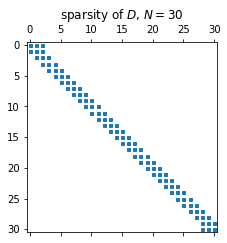

In [10]:
tj, D, F = assemble(a, b, c, f, alpha0, alpha1, beta0, beta1, N=6)
with np.printoptions(precision=1, suppress=True, linewidth=120):
    print(D.toarray())

tj, D, F = assemble(a, b, c, f, alpha0, alpha1, beta0, beta1, N=30)
fig, ax = plt.subplots(figsize=(3.5, 3.5))
ax.spy(D, markersize=3)
ax.set_title(r"sparsity of $D$, $N = 30$")
plt.show()

## Solve and compare with the exact solution

N =   4: max error = 1.044e+00
N =   8: max error = 2.683e-01
N =  16: max error = 6.677e-02


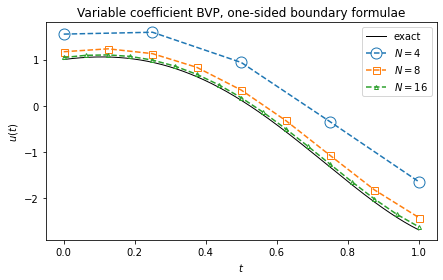

In [11]:
t_fine = np.linspace(0, 1, 500)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(t_fine, u_exact(t_fine), "k-", linewidth=1, label="exact")
for N, marker, ms in zip([4, 8, 16], ["o", "s", "^"], [11, 7, 4]):
    tj, u = solve_one_sided(a, b, c, f, alpha0, alpha1, beta0, beta1, N)
    err = np.max(np.abs(u - u_exact(tj)))
    print(f"N = {N:3d}: max error = {err:.3e}")
    ax.plot(tj, u, marker=marker, linestyle="--", markersize=ms, markerfacecolor="none", label=rf"$N = {N}$")
ax.set_xlabel(r"$t$")
ax.set_ylabel(r"$u(t)$")
ax.set_title("Variable coefficient BVP, one-sided boundary formulae")
ax.legend()
plt.show()

## Option 2: centered differences with ghost points

Instead of one-sided formulae we can add the ghost points $t_{-1} = -\Delta t$ and $t_{N+1} = 1 + \Delta t$ and use
centered differences in the boundary conditions,
$$
a_0 \frac{u_1 - u_{-1}}{2\Delta t} - \alpha_0 u_0 = \beta_0, \qquad
a_N \frac{u_{N+1} - u_{N-1}}{2\Delta t} - \alpha_1 u_N = \beta_1 .
$$
We now have $N+3$ unknowns $u_{-1}, \dots, u_{N+1}$, so we also impose the discrete ODE at $t_0$ and $t_N$.
This gives $N+1$ ODE rows plus $2$ boundary rows. In the code, unknown $u_j$ is stored at index $j+1$.

Note that the ODE row at $t_0$ needs $a(t_{-1/2})$ and the one at $t_N$ needs $a(t_{N+1/2})$, so $a$ must be
defined slightly outside $[0,1]$.

In [12]:
def solve_ghost(a, b, c, f, alpha0, alpha1, beta0, beta1, N):
    tj, dt = make_grid(N)
    M = N + 3  # unknowns u_{-1}, ..., u_{N+1}
    D = sparse.lil_matrix((M, M))
    F = np.zeros(M)

    # discrete ODE at t_0, ..., t_N (rows 1, ..., N+1)
    for j in range(N + 1):
        k = j + 1  # index of u_j
        a_minus, a_plus = a(tj[j] - dt / 2), a(tj[j] + dt / 2)
        bj, cj = b(tj[j]), c(tj[j])
        D[k, k - 1] = -a_minus / dt**2 - bj / (2 * dt)
        D[k, k] = (a_minus + a_plus) / dt**2 + cj
        D[k, k + 1] = -a_plus / dt**2 + bj / (2 * dt)
        F[k] = f(tj[j])

    # boundary conditions (rows 0 and N+2)
    a0, aN = a(tj[0]), a(tj[N])
    D[0, 0] = -a0 / (2 * dt)              # u_{-1}
    D[0, 1] = -alpha0                     # u_0
    D[0, 2] = a0 / (2 * dt)               # u_1
    F[0] = beta0
    D[M - 1, M - 3] = -aN / (2 * dt)      # u_{N-1}
    D[M - 1, M - 2] = -alpha1             # u_N
    D[M - 1, M - 1] = aN / (2 * dt)       # u_{N+1}
    F[M - 1] = beta1

    u = spsolve(D.tocsr(), F)
    return tj, u[1:-1]  # drop the ghost values

## Convergence study

We measure the maximum error $E_N = \max_j |u_j - u(t_j)|$ for both treatments of the boundary conditions
on a sequence of grids. For a second order method, $E_N \approx C N^{-2}$, so the error should drop by a
factor of about $4$ each time $N$ is doubled, and the log-log plot should have slope $-2$.

     N |  one-sided  rate |      ghost  rate
     8 |  2.683e-01   nan |  4.303e-02   nan
    16 |  6.677e-02  2.01 |  1.068e-02  2.01
    32 |  1.661e-02  2.01 |  2.667e-03  2.00
    64 |  4.141e-03  2.00 |  6.664e-04  2.00
   128 |  1.034e-03  2.00 |  1.666e-04  2.00
   256 |  2.582e-04  2.00 |  4.164e-05  2.00
   512 |  6.452e-05  2.00 |  1.041e-05  2.00
  1024 |  1.613e-05  2.00 |  2.603e-06  2.00
  2048 |  4.032e-06  2.00 |  6.507e-07  2.00
  4096 |  1.008e-06  2.00 |  1.627e-07  2.00


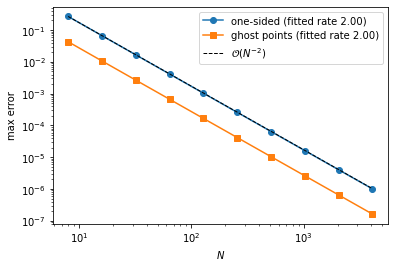

In [13]:
Ns = 2 ** np.arange(3, 13)
errors = {"one-sided": [], "ghost points": []}
for N in Ns:
    for name, solver in [("one-sided", solve_one_sided), ("ghost points", solve_ghost)]:
        tj, u = solver(a, b, c, f, alpha0, alpha1, beta0, beta1, N)
        errors[name].append(np.max(np.abs(u - u_exact(tj))))

print(f"{'N':>6} | {'one-sided':>10} {'rate':>5} | {'ghost':>10} {'rate':>5}")
for i, N in enumerate(Ns):
    row = f"{N:6d}"
    for name in errors:
        E = errors[name]
        rate = np.log2(E[i - 1] / E[i]) if i > 0 else np.nan
        row += f" | {E[i]:10.3e} {rate:5.2f}"
    print(row)

fig, ax = plt.subplots(figsize=(6, 4))
for (name, E), marker in zip(errors.items(), ["o", "s"]):
    p = -np.polyfit(np.log(Ns), np.log(E), 1)[0]
    ax.loglog(Ns, E, marker=marker, label=f"{name} (fitted rate {p:.2f})")
ax.loglog(Ns, errors["one-sided"][0] * (Ns / Ns[0]) ** -2.0, "k--", linewidth=1, label=r"$\mathcal{O}(N^{-2})$")
ax.set_xlabel(r"$N$")
ax.set_ylabel(r"max error")
ax.legend()
plt.show()

Both methods converge at second order, as predicted. The ghost point version usually has a somewhat
smaller error constant: the centered difference for $u'$ has leading error $\frac{\Delta t^2}{6} u'''$ while
the one-sided formulae have $\frac{\Delta t^2}{3} u'''$.

**Things to try:**
- Make $a$ vary rapidly, e.g. `a_expr = 1 + 0.9 * sp.tanh(20 * (t - sp.Rational(1, 2)))`. The method is
  still second order, but you need a finer grid before you see the asymptotic rate.
- Make the advection large compared to diffusion, e.g. `b_expr = 50 + 0*t` with `a_expr = 1 + 0*t`.
  What happens to the solution on coarse grids? (Look up the *cell Péclet number* $|b|\Delta t / a$.)
- Replace one of the second order boundary formulae by a first order one, e.g. $u'(t_0) \approx (u_1 - u_0)/\Delta t$.
  What happens to the convergence rate of the *whole* solution?

## Playground: set $f$ and $\beta$ directly

Here there is no manufactured solution: define `numpy` functions for $a, b, c, f$ and pick the constants
$\alpha_0, \alpha_1, \beta_0, \beta_1$ yourself. Without an exact solution we judge accuracy by comparing
successive grid refinements. Here the left end has a flux (Neumann) condition ($\alpha_0 = 0$) and
the right end a Robin condition.

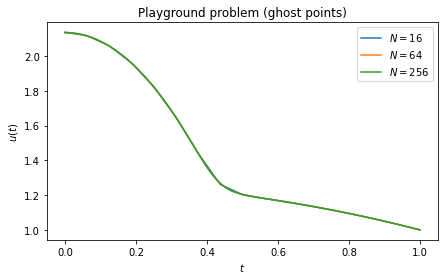

In [14]:
a_p = lambda x: 1 + 0.9 * np.tanh(20 * (x - 0.5))   # coefficient jumps from ~0.1 to ~1.9
b_p = lambda x: 0 * x
c_p = lambda x: 0 * x
f_p = lambda x: np.ones_like(x)
alpha0_p, beta0_p = 0.0, 0.0   # a u'(0) = 0
alpha1_p, beta1_p = -1.0, 0.0  # a u'(1) = -u(1)

fig, ax = plt.subplots(figsize=(7, 4))
for N in [16, 64, 256]:
    tj, u = solve_ghost(a_p, b_p, c_p, f_p, alpha0_p, alpha1_p, beta0_p, beta1_p, N)
    ax.plot(tj, u, label=rf"$N = {N}$")
ax.set_xlabel(r"$t$")
ax.set_ylabel(r"$u(t)$")
ax.set_title("Playground problem (ghost points)")
ax.legend()
plt.show()